# Exploratory_Data_Analysis

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
# import dataset
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

orders_cleaned      = pd.read_csv('../data/interim/olist_orders_cleaned.csv', parse_dates=date_cols)
order_items_cleaned = pd.read_csv('../data/interim/olist_order_items_cleaned.csv')
customers_cleaned   = pd.read_csv('../data/interim/olist_customers_cleaned.csv')
payments_cleaned    = pd.read_csv('../data/interim/olist_ payments_cleaned.csv')
products_cleaned    = pd.read_csv('../data/interim/olist_products_cleaned.csv')
translation_cleaned = pd.read_csv('../data/interim/olist_ translation_cleaned.csv')
geolocation_cleaned = pd.read_csv('../data/interim/olist_geolocation_cleaned.csv')
reviews_cleaned     = pd.read_csv('../data/interim/olist_ reviews_cleaned.csv')
sellers_cleaned     = pd.read_csv('../data/interim/olist_sellers_cleaned.csv')

## EDA-01 — Univariate Analysis

In [44]:
orders_cleaned.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
purchase_to_approved_hours              float64
approval_to_carrier_hours               float64
carrier_to_customer_hours               float64
purchase_to_customer_hours              float64
purchase_to_estimated_hours             float64
dtype: object

In [45]:
orders_cleaned.sample(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_to_approved_hours,approval_to_carrier_hours,carrier_to_customer_hours,purchase_to_customer_hours,purchase_to_estimated_hours
45879,526adb0ce5a810e18af0b00b46011957,61febd8ff905215bbdd5d259d519fbd0,delivered,2017-02-14 14:34:43,2017-02-15 02:45:19,2017-02-15 12:14:37,2017-02-22 10:12:14,2017-03-27,12.176667,9.488333,165.960278,187.625278,969.421389
34444,43c77c1881febf0c89c17b98fa782d6d,23922448e9b4204253e23526929255a2,delivered,2017-10-04 14:12:12,2017-10-04 14:28:54,2017-10-09 21:35:58,2017-10-17 14:13:07,2017-10-27,0.278333,127.117778,184.619167,312.015278,537.796667


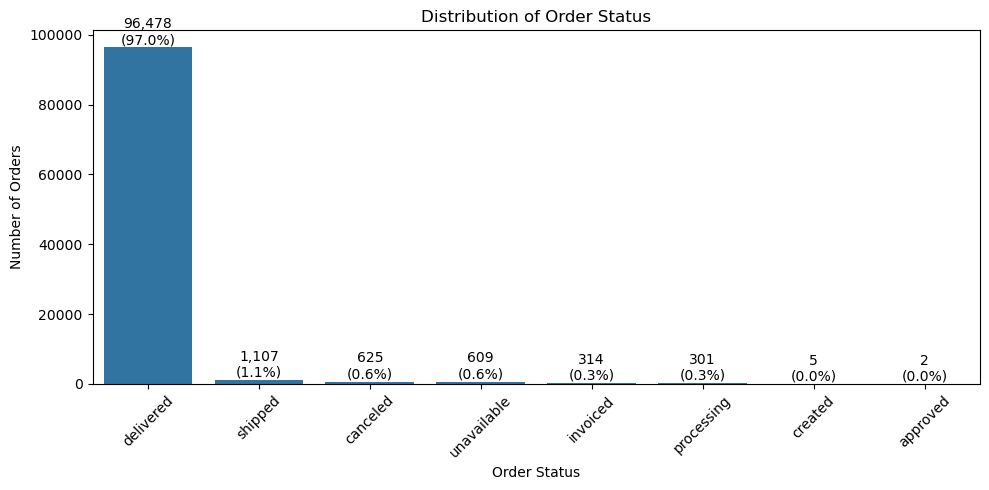

In [46]:
order_status_counts = orders_cleaned["order_status"].value_counts()
total_orders = order_status_counts.sum()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=order_status_counts.index,
    y=order_status_counts.values
    
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

# Add count and percentage labels
for bar in ax.patches:
    count = bar.get_height()
    percentage = (count / total_orders) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{int(count):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

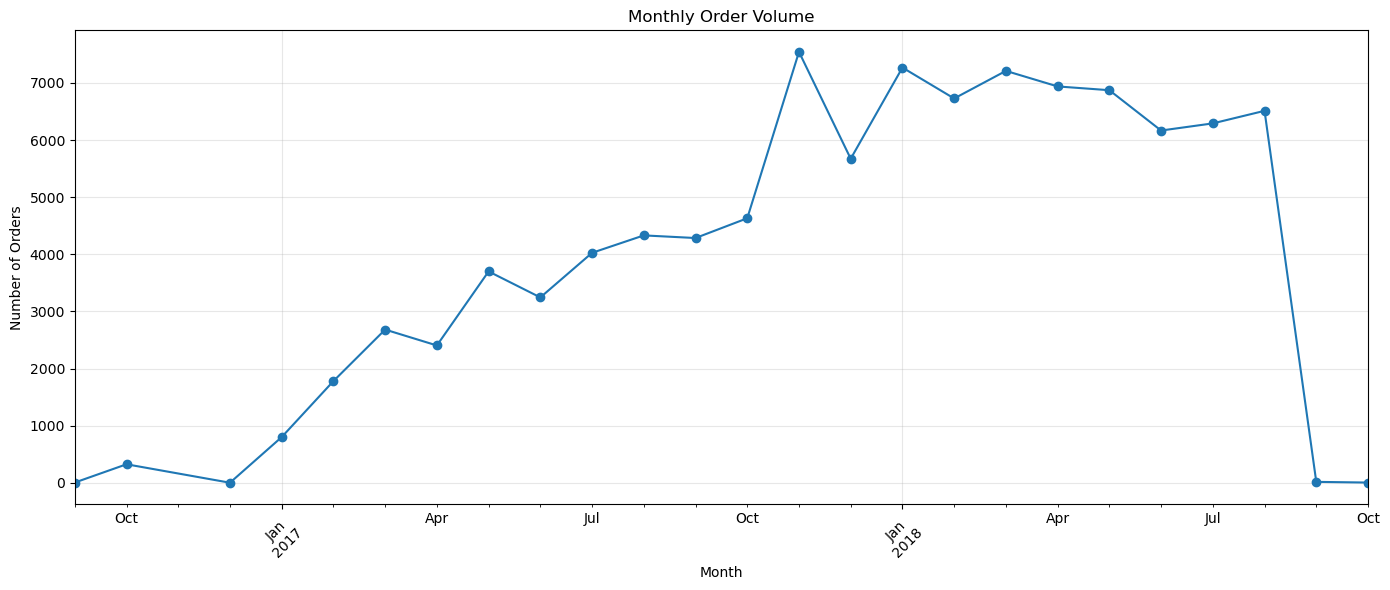

In [47]:
monthly_orders = (
    orders_cleaned.groupby(orders_cleaned['order_purchase_timestamp'].dt.to_period("M")).size()
    )
monthly_orders

plt.figure(figsize=(14, 6))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [49]:
for col in ['purchase_to_approved_hours','approval_to_carrier_hours',
            'carrier_to_customer_hours','purchase_to_customer_hours',
            'purchase_to_estimated_hours']:
    n_neg = (orders_cleaned[col] < 0).sum()
    pct = n_neg / orders_cleaned[col].notna().sum() * 100
    print(f"{col}:  {n_neg}  ({pct:.3f}%) Negative row ")

purchase_to_approved_hours:  0  (0.000%) Negative row 
approval_to_carrier_hours:  1359  (1.392%) Negative row 
carrier_to_customer_hours:  23  (0.024%) Negative row 
purchase_to_customer_hours:  0  (0.000%) Negative row 
purchase_to_estimated_hours:  0  (0.000%) Negative row 


In [51]:
orders_cleaned['approval_to_carrier_hours'].loc[orders_cleaned['approval_to_carrier_hours'] < 0].describe()

count    1359.000000
mean      -24.751987
std       115.307793
min     -4109.256111
25%       -25.956667
50%       -17.167778
75%        -1.415417
max        -0.005833
Name: approval_to_carrier_hours, dtype: float64

In [55]:
orders_cleaned['order_status'].loc[orders_cleaned['approval_to_carrier_hours'] < 0].value_counts()

order_status
delivered    1350
shipped         9
Name: count, dtype: int64

In [52]:
orders_cleaned['carrier_to_customer_hours'].loc[orders_cleaned['carrier_to_customer_hours'] < 0].describe()

count     23.000000
mean     -78.455133
std       89.308070
min     -386.308056
25%     -128.759028
50%      -39.864444
75%      -23.338333
max       -0.388333
Name: carrier_to_customer_hours, dtype: float64

In [56]:
orders_cleaned['order_status'].loc[orders_cleaned['carrier_to_customer_hours'] < 0].value_counts()

order_status
delivered    23
Name: count, dtype: int64